In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
import math
from IPython.display import Javascript

Javascript("""
window.jupyterapp.commands.execute('runmenu:run-all');
""")


def norma_vector(x):
    suma = 0.0
    x_flat = np.ravel(x)

    for val in x_flat:
        suma += float(val) ** 2

    return math.sqrt(suma)


def norma_matrice(A):
    suma = 0.0
    m, n = A.shape

    for i in range(m):
        for j in range(n):
            suma += float(A[i, j]) ** 2

    return math.sqrt(suma)


def norma_offdiag(A):
    n = A.shape[0]
    suma = 0.0

    for i in range(n):
        for j in range(n):
            if i != j:
                suma += float(A[i, j]) ** 2

    return math.sqrt(suma)


def qr_gram_schmidt(A, eps=1e-12):
    A = A.astype(float)
    m, n = A.shape

    Q = np.zeros((m, n))
    R = np.zeros((n, n))

    for k in range(n):
        v = A[:, k].copy()

        for j in range(k):
            R[j, k] = Q[:, j].T @ A[:, k]
            v = v - R[j, k] * Q[:, j]

        R[k, k] = norma_vector(v)

        if R[k, k] < eps:
            Q[:, k] = np.zeros(m)
        else:
            Q[:, k] = v / R[k, k]

    return Q, R


def tridiagonalizare_householder(A, eps=1e-12):
    A = A.astype(float).copy()
    n = A.shape[0]

    Q_total = np.eye(n)

    for k in range(n - 2):
        x = A[k + 1:, k].copy()

        norm_x = norma_vector(x)

        if norm_x < eps:
            continue

        e1 = np.zeros_like(x)
        e1[0] = 1.0

        if x[0] >= 0:
            alpha = -norm_x
        else:
            alpha = norm_x

        v = x - alpha * e1
        norm_v = norma_vector(v)

        if norm_v < eps:
            continue

        v = v / norm_v

        H_small = np.eye(n - k - 1) - 2.0 * np.outer(v, v)

        H = np.eye(n)
        H[k + 1:, k + 1:] = H_small

        A = H @ A @ H
        Q_total = Q_total @ H

    T = (A + A.T) / 2.0

    return Q_total, T


def valori_vectori_proprii_simetrica(A, max_iter=5000, tol=1e-10):
    A = A.astype(float)
    n = A.shape[0]

    Q_householder, T = tridiagonalizare_householder(A)

    Q_total = np.eye(n)

    for iteratie in range(max_iter):
        eroare = norma_offdiag(T)

        if eroare < tol:
            break

        Q, R = qr_gram_schmidt(T)

        T = R @ Q
        Q_total = Q_total @ Q

    eigenvalues = np.zeros(n)

    for i in range(n):
        eigenvalues[i] = T[i, i]

    eigenvectors = Q_householder @ Q_total

    for j in range(n):
        norm_col = norma_vector(eigenvectors[:, j])

        if norm_col > tol:
            eigenvectors[:, j] = eigenvectors[:, j] / norm_col

    eroare_finala = norma_offdiag(T)

    return eigenvalues, eigenvectors, iteratie + 1, eroare_finala


def sorteaza_descrescator(valori, vectori):
    valori = valori.copy()
    vectori = vectori.copy()

    n = len(valori)

    for i in range(n - 1):
        poz_max = i

        for j in range(i + 1, n):
            if valori[j] > valori[poz_max]:
                poz_max = j

        if poz_max != i:
            aux = valori[i]
            valori[i] = valori[poz_max]
            valori[poz_max] = aux

            aux_vec = vectori[:, i].copy()
            vectori[:, i] = vectori[:, poz_max]
            vectori[:, poz_max] = aux_vec

    return valori, vectori


def svd_custom(A, eps=1e-10):
    A = A.astype(float)
    m, n = A.shape

    B = A.T @ A

    valori_proprii, V, nr_iteratii, eroare_qr = valori_vectori_proprii_simetrica(B)

    valori_proprii, V = sorteaza_descrescator(valori_proprii, V)

    for i in range(len(valori_proprii)):
        if valori_proprii[i] < 0 and abs(valori_proprii[i]) < eps:
            valori_proprii[i] = 0.0

    valori_singulare = []
    vectori_V_validi = []

    for i in range(len(valori_proprii)):
        if valori_proprii[i] > eps:
            sigma = math.sqrt(valori_proprii[i])
            valori_singulare.append(sigma)
            vectori_V_validi.append(V[:, i])

    r = len(valori_singulare)

    S = np.array(valori_singulare)
    V_valid = np.array(vectori_V_validi).T

    U = np.zeros((m, r))

    for i in range(r):
        sigma = S[i]
        v_i = V_valid[:, i]

        u_i = A @ v_i / sigma

        norm_u = norma_vector(u_i)

        if norm_u > eps:
            u_i = u_i / norm_u

        U[:, i] = u_i

    Vt = V_valid.T

    return U, S, Vt


def reconstruieste_svd(U, S, Vt):
    return (U * S) @ Vt

In [42]:
A = np.array([
    [3, 1, 1],
    [-1, 3, 1],
    [0, 2, 4],
    [2, 0, 1]
], dtype=float)

U, S, Vt = svd_custom(A)

A_rec = reconstruieste_svd(U, S, Vt)

eroare = norma_matrice(A - A_rec)

print("Matricea A:")
print(A)

print("\nValorile singulare S:")
print(S)

print("\nA reconstruit:")
print(A_rec)

print("\nEroare reconstructie:")
print(eroare)

print("\nU.T @ U:")
print(U.T @ U)

print("\nVt @ Vt.T:")
print(Vt @ Vt.T)

I_U = U.T @ U
I_V = Vt @ Vt.T

eroare_U = norma_matrice(I_U - np.eye(I_U.shape[0]))
eroare_V = norma_matrice(I_V - np.eye(I_V.shape[0]))

print("\nEroare ortogonalitate U:", eroare_U)
print("Eroare ortogonalitate V:", eroare_V)

assert eroare < 1e-7, "Eroarea de reconstructie este prea mare."
assert eroare_U < 1e-7, "Coloanele lui U nu sunt ortonormale."
assert eroare_V < 1e-7, "Coloanele lui V nu sunt ortonormale."

print("\nPasul 1 trecut: SVD custom functioneaza pe matricea de test.")

Matricea A:
[[ 3.  1.  1.]
 [-1.  3.  1.]
 [ 0.  2.  4.]
 [ 2.  0.  1.]]

Valorile singulare S:
[5.42160465 3.74165739 1.89900054]

A reconstruit:
[[ 3.00000000e+00  1.00000000e+00  1.00000000e+00]
 [-1.00000000e+00  3.00000000e+00  1.00000000e+00]
 [ 2.00746330e-15  2.00000000e+00  4.00000000e+00]
 [ 2.00000000e+00  1.21751522e-15  1.00000000e+00]]

Eroare reconstructie:
7.248155470844961e-15

U.T @ U:
[[ 1.00000000e+00 -2.05911047e-12 -2.35080648e-15]
 [-2.05911047e-12  1.00000000e+00 -1.84784511e-16]
 [-2.35080648e-15 -1.84784511e-16  1.00000000e+00]]

Vt @ Vt.T:
[[ 1.00000000e+00  2.66841047e-16 -1.14754551e-15]
 [ 2.66841047e-16  1.00000000e+00 -8.85160860e-17]
 [-1.14754551e-15 -8.85160860e-17  1.00000000e+00]]

Eroare ortogonalitate U: 2.9120238846401993e-12
Eroare ortogonalitate V: 1.685557382130764e-15

Pasul 1 trecut: SVD custom functioneaza pe matricea de test.


In [32]:
print(S)
print(eroare)
print(eroare_U)
print(eroare_V)

[5.42160465 3.74165739 1.89900054]
7.248155470844961e-15
2.9120238846401993e-12
1.685557382130764e-15


In [33]:
B = np.array([
    [1, 2],
    [3, 4],
    [5, 6],
    [7, 8]
], dtype=float)

U, S, Vt = svd_custom(B)
B_rec = reconstruieste_svd(U, S, Vt)

eroare_B = norma_matrice(B - B_rec)

print("S pentru B:")
print(S)

print("Eroare reconstructie B:")
print(eroare_B)

assert eroare_B < 1e-7

print("Test suplimentar trecut.")

S pentru B:
[14.2690955   0.62682823]
Eroare reconstructie B:
6.170817721920519e-13
Test suplimentar trecut.


images.shape = (400, 64, 64)
data.shape   = (400, 4096)
labels.shape = (400,)
Valoare minima pixel: 0.0
Valoare maxima pixel: 1.0
Primele 20 etichete:
[0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]

X_total.shape = (4096, 400)
y_total.shape = (400,)

X.shape = (4096, 25)
y.shape = (25,)
Etichete subset:
[0 0 0 0 0 1 1 1 1 1 2 2 2 2 2 3 3 3 3 3 4 4 4 4 4]

Pasul 2 trecut: datasetul Olivetti a fost incarcat si pregatit corect.


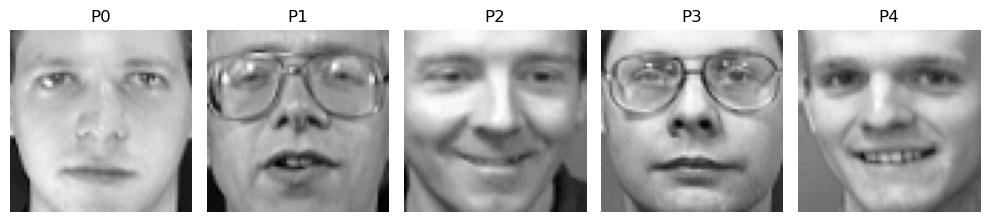

In [56]:
from sklearn.datasets import fetch_olivetti_faces
import matplotlib.pyplot as plt
import numpy as np


def incarca_olivetti():
    """
    Incarca datasetul Olivetti Faces.

    Returneaza:
        images - imagini de forma (400, 64, 64)
        data   - imagini vectorizate de forma (400, 4096)
        labels - etichete de forma (400,)
    """
    dataset = fetch_olivetti_faces(shuffle=False)

    images = dataset.images
    data = dataset.data
    labels = dataset.target

    return images, data, labels


def selecteaza_subset_olivetti(X_total, y_total, nr_persoane=5, imagini_per_persoana=5):
    """
    Selecteaza un subset mic din Olivetti.
    """
    indici_selectati = []

    for persoana in range(nr_persoane):
        indici_persoana = np.where(y_total == persoana)[0]

        for j in range(imagini_per_persoana):
            indici_selectati.append(indici_persoana[j])

    X_subset = X_total[:, indici_selectati]
    y_subset = y_total[indici_selectati]

    return X_subset, y_subset, indici_selectati
afiseaza_fata_medie(mean_face, image_shape=(64, 64))

def afiseaza_o_imagine_per_persoana(X, y, image_shape=(64, 64)):

    persoane = np.unique(y)
    nr = len(persoane)

    plt.figure(figsize=(2 * nr, 3))

    for idx, persoana in enumerate(persoane):
        index_imagine = np.where(y == persoana)[0][0]
        img = X[:, index_imagine].reshape(image_shape)

        plt.subplot(1, nr, idx + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"P{persoana}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# 1. Incarcam datasetul
images, data, labels = incarca_olivetti()

print("images.shape =", images.shape)
print("data.shape   =", data.shape)
print("labels.shape =", labels.shape)

print("Valoare minima pixel:", data.min())
print("Valoare maxima pixel:", data.max())

print("Primele 20 etichete:")
print(labels[:20])


# 2. Construim matricea X_total
X_total = data.T
y_total = labels.copy()

print("\nX_total.shape =", X_total.shape)
print("y_total.shape =", y_total.shape)


# 3. Selectam subsetul mic
X, y, indici = selecteaza_subset_olivetti(
    X_total,
    y_total,
    nr_persoane=5,
    imagini_per_persoana=5
)

print("\nX.shape =", X.shape)
print("y.shape =", y.shape)
print("Etichete subset:")
print(y)


# 4. Teste automate
assert images.shape == (400, 64, 64), "Forma images nu este corecta."
assert data.shape == (400, 4096), "Forma data nu este corecta."
assert labels.shape == (400,), "Forma labels nu este corecta."

assert X_total.shape == (4096, 400), "X_total nu are forma corecta."
assert y_total.shape == (400,), "y_total nu are forma corecta."

assert X.shape == (4096, 25), "X subset nu are forma corecta."
assert y.shape == (25,), "y subset nu are forma corecta."

assert X.min() >= 0.0, "Pixelii ar trebui sa fie >= 0."
assert X.max() <= 1.0, "Pixelii ar trebui sa fie <= 1."

print("\nPasul 2 trecut: datasetul Olivetti a fost incarcat si pregatit corect.")


# 5. Afisam subsetul
afiseaza_o_imagine_per_persoana(X, y, image_shape=(64, 64))

In [54]:
print(X.shape)
print(y.shape)
print(y)

(4096, 25)
(25,)
[0 0 0 0 0 1 1 1 1 1 2 2 2 2 2 3 3 3 3 3 4 4 4 4 4]


In [63]:
def calculeaza_fata_medie(X):
    """
    Calculeaza fata medie pentru matricea X.

    X are forma:
        (numar_pixeli, numar_imagini)

    Returneaza:
        mean_face cu forma (numar_pixeli, 1)
    """
    numar_pixeli, numar_imagini = X.shape

    mean_face = np.zeros((numar_pixeli, 1))

    for i in range(numar_imagini):
        mean_face[:, 0] = mean_face[:, 0] + X[:, i]

    mean_face[:, 0] = mean_face[:, 0] / numar_imagini

    return mean_face

In [65]:
mean_face = calculeaza_fata_medie(X)

print("mean_face.shape =", mean_face.shape)
print("Valoare minima fata medie:", mean_face.min())
print("Valoare maxima fata medie:", mean_face.max())

mean_face.shape = (4096, 1)
Valoare minima fata medie: 0.23702479258179665
Valoare maxima fata medie: 0.7842975187301636


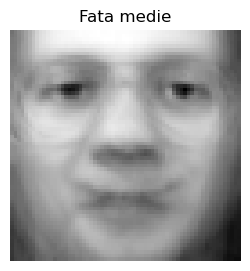

In [67]:
def afiseaza_fata_medie(mean_face, image_shape=(64, 64)):
    """
    Afiseaza fata medie.
    """
    img = mean_face.reshape(image_shape)

    plt.figure(figsize=(3, 3))
    plt.imshow(img, cmap="gray")
    plt.title("Fata medie")
    plt.axis("off")
    plt.show()

afiseaza_fata_medie(mean_face, image_shape=(64, 64))

In [97]:
def centreaza_datele(X, mean_face):
    """
    Centreaza datele scazand fata medie din fiecare imagine.

    X are forma:
        (numar_pixeli, numar_imagini)

    mean_face are forma:
        (numar_pixeli, 1)

    Returneaza:
        X_centrata cu aceeasi forma ca X
    """
    numar_pixeli, numar_imagini = X.shape

    X_centrata = np.zeros_like(X)

    for i in range(numar_imagini):
        X_centrata[:, i] = X[:, i] - mean_face[:, 0]

    return X_centrata
    

In [71]:
X_centrata = centreaza_datele(X, mean_face)

print("X.shape =", X.shape)
print("X_centrata.shape =", X_centrata.shape)

print("Min X_centrata:", X_centrata.min())
print("Max X_centrata:", X_centrata.max())

X.shape = (4096, 25)
X_centrata.shape = (4096, 25)
Min X_centrata: -0.5786777
Max X_centrata: 0.4928926


In [73]:
def verifica_media_centrata(X_centrata):
    """
    Verifica daca media pe coloane este aproape zero.
    """
    numar_pixeli, numar_imagini = X_centrata.shape

    medie = np.zeros((numar_pixeli, 1))

    for i in range(numar_imagini):
        medie[:, 0] = medie[:, 0] + X_centrata[:, i]

    medie[:, 0] = medie[:, 0] / numar_imagini

    eroare_medie = norma_vector(medie)

    return eroare_medie  

In [91]:
eroare_medie = verifica_media_centrata(X_centrata)
print(eroare_medie)
print("Eroare medie dupa centrare:", eroare_medie)

assert eroare_medie < 1e-6, "Datele nu sunt centrate corect."

print("Pasul 3 trecut: fata medie si centrarea datelor functioneaza corect.")

8.232301355372124e-08
Eroare medie dupa centrare: 8.232301355372124e-08
Pasul 3 trecut: fata medie si centrarea datelor functioneaza corect.


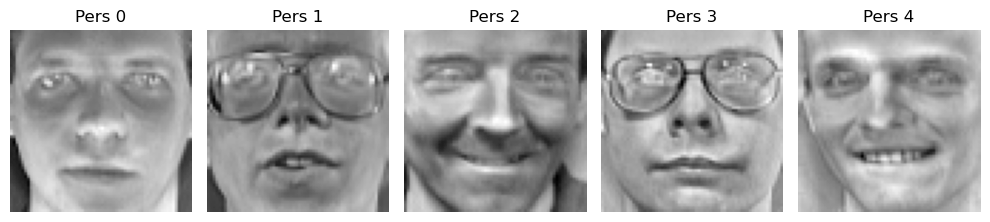

In [125]:
def afiseaza_imagini_centrate_head(X_centrata, y, image_shape=(64, 64), nr=20):
    """
    Afiseaza primele imagini centrate.
    """
    nr = min(nr, X_centrata.shape[1])

    plt.figure(figsize=(2 * nr, 3))

    for i in range(nr):
        img = X_centrata[:, i].reshape(image_shape)

        plt.subplot(1, nr, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Img {i}, Pers {y[i]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def afiseaza_o_imagine_centrata_per_persoana(X_centrata, y, image_shape=(64, 64)):
    persoane = np.unique(y)
    nr = len(persoane)

    plt.figure(figsize=(2 * nr, 3))

    for idx, persoana in enumerate(persoane):
        index_imagine = np.where(y == persoana)[0][0]
        img = X_centrata[:, index_imagine].reshape(image_shape)

        plt.subplot(1, nr, idx + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Pers {persoana}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

afiseaza_o_imagine_centrata_per_persoana(X_centrata, y)

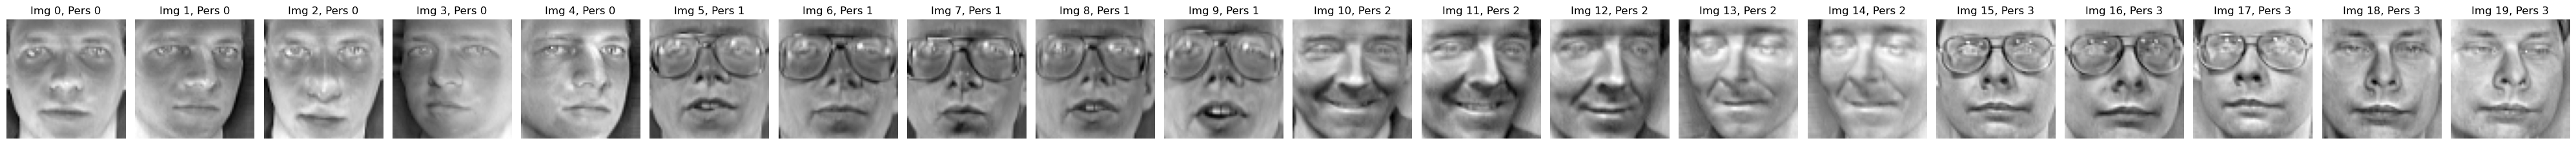

In [128]:
 afiseaza_imagini_centrate_head(X_centrata, y)

In [130]:
U, S, Vt = svd_custom(X_centrata)

print("U.shape  =", U.shape)
print("S.shape  =", S.shape)
print("Vt.shape =", Vt.shape)

print("\nPrimele valori singulare:")
print(S[:10])

U.shape  = (4096, 24)
S.shape  = (24,)
Vt.shape = (24, 25)

Primele valori singulare:
[19.93650681 16.93175928 13.9431523  10.21632567  9.33754307  8.4830385
  7.78376683  6.23843211  6.06857108  5.75873937]


In [136]:
X_rec = reconstruieste_svd(U, S, Vt)

eroare_svd = norma_matrice(X_centrata - X_rec)

print("Eroare reconstructie SVD pentru X_centrata:")
print(eroare_svd)

print("---------------------------------------------------------")

eroare_relativa_svd = norma_matrice(X_centrata - X_rec) / norma_matrice(X_centrata)

print("Eroare relativa SVD:")
print(eroare_relativa_svd)

Eroare reconstructie SVD pentru X_centrata:
4.104894667957682e-07
---------------------------------------------------------
Eroare relativa SVD:
1.0575286885141132e-08


In [138]:
assert eroare_relativa_svd < 1e-6, "SVD-ul nu reconstruieste suficient de bine X_centrata."

print("SVD aplicat pe X_centrata functioneaza corect.")

SVD aplicat pe X_centrata functioneaza corect.


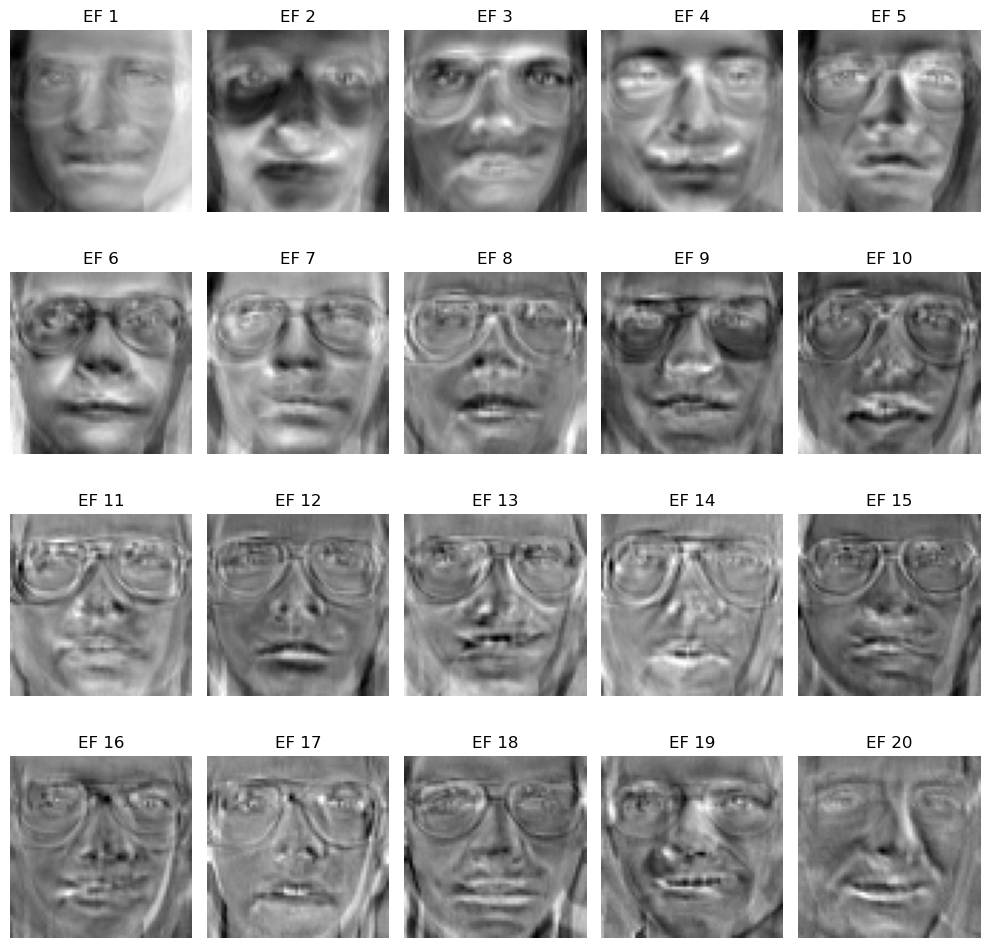

In [154]:
def afiseaza_eigenfaces(U, image_shape=(64, 64), nr=20):
    """
    Afiseaza primele nr eigenfaces. Functia transforma coloanele unei matrici in imagini, fiecare coloana = o imagine. EF = coloana. 
    Pozele afisate sunt direcții principale de variație ale fețelor față de fața medie.
    n Eigenfaces, ideea este următoarea:
    
    Calculezi fața medie.
    Scazi fața medie din fiecare imagine.
    Aplici SVD pe imaginile centrate.
    Coloanele lui U îți spun în ce direcții variază cel mai mult fețele.
    """
    nr = min(nr, U.shape[1])

    coloane = 5
    randuri = int(np.ceil(nr / coloane))

    plt.figure(figsize=(2 * coloane, 2.5 * randuri))

    for i in range(nr):
        eigenface = U[:, i].reshape(image_shape)

        plt.subplot(randuri, coloane, i + 1)
        plt.imshow(eigenface, cmap="gray")
        plt.title(f"EF {i + 1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
afiseaza_eigenfaces(U, image_shape=(64, 64), nr=20) 

In [146]:
def energie_pastrata(S, k):
    """
    Calculeaza energia pastrata de primele k valori singulare.
    """
    k = min(k, len(S))

    suma_k = 0.0
    suma_totala = 0.0

    for i in range(len(S)):
        suma_totala += S[i] ** 2

    for i in range(k):
        suma_k += S[i] ** 2

    return suma_k / suma_totala
for k_test in [1, 2, 3, 5, 10, 15, 20]:
    if k_test <= len(S):
        e = energie_pastrata(S, k_test)
        print(f"k = {k_test:2d} | energie pastrata = {e:.4f}")

k =  1 | energie pastrata = 0.2638
k =  2 | energie pastrata = 0.4541
k =  3 | energie pastrata = 0.5831
k =  5 | energie pastrata = 0.7103
k = 10 | energie pastrata = 0.8705
k = 15 | energie pastrata = 0.9480
k = 20 | energie pastrata = 0.9889


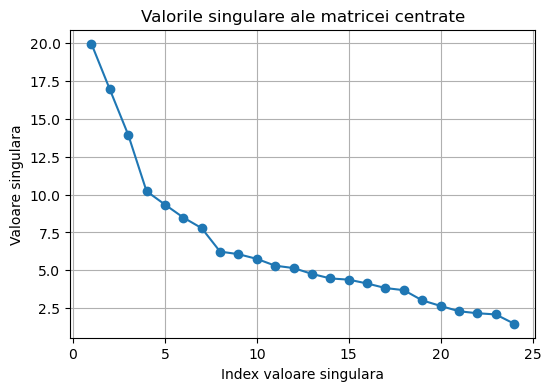

In [148]:
def afiseaza_valori_singulare(S):
    """
    Afiseaza valorile singulare.
    """
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(S) + 1), S, marker="o")
    plt.xlabel("Index valoare singulara")
    plt.ylabel("Valoare singulara")
    plt.title("Valorile singulare ale matricei centrate")
    plt.grid(True)
    plt.show()
afiseaza_valori_singulare(S)    

In [150]:
print("Rezumat Pasul 4")
print("----------------")
print("X_centrata.shape =", X_centrata.shape)
print("U.shape          =", U.shape)
print("S.shape          =", S.shape)
print("Vt.shape         =", Vt.shape)
print("Eroare relativa  =", eroare_relativa_svd)

assert U.shape[0] == X_centrata.shape[0], "U nu are numarul corect de linii."
assert Vt.shape[1] == X_centrata.shape[1], "Vt nu are numarul corect de coloane."
assert len(S) == U.shape[1], "S si U nu sunt compatibile."
assert len(S) == Vt.shape[0], "S si Vt nu sunt compatibile."
assert eroare_relativa_svd < 1e-6, "Reconstrucția SVD nu este suficient de buna."

print("\nPasul 4 trecut: SVD-ul a fost aplicat pe imaginile centrate si eigenfaces au fost obtinute.")

Rezumat Pasul 4
----------------
X_centrata.shape = (4096, 25)
U.shape          = (4096, 24)
S.shape          = (24,)
Vt.shape         = (24, 25)
Eroare relativa  = 1.0575286885141132e-08

Pasul 4 trecut: SVD-ul a fost aplicat pe imaginile centrate si eigenfaces au fost obtinute.


In [156]:
#Reconstructie
index_imagine = 0
x_original = X[:, index_imagine].reshape(-1, 1)

print("x_original.shape =", x_original.shape)
print("Persoana:", y[index_imagine])


x_original.shape = (4096, 1)
Persoana: 0


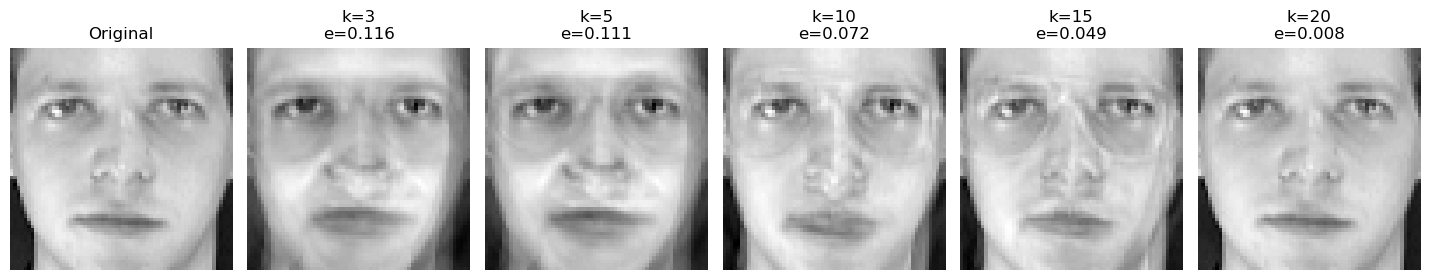

In [160]:
def reconstruieste_fata_cu_k(x, mean_face, U, k):
    """
    Reconstruieste o fata folosind primele k eigenfaces.

    Parametri:
        x         - imagine vectorizata, forma (4096, 1) sau (4096,)
        mean_face - fata medie, forma (4096, 1)
        U         - matricea eigenfaces, forma (4096, r)
        k         - numarul de eigenfaces folosite

    Returneaza:
        x_reconstruit - imagine reconstruita, forma (4096, 1)
    """
    if len(x.shape) == 1:
        x = x.reshape(-1, 1)

    k = min(k, U.shape[1])

    U_k = U[:, :k]

    x_c = x - mean_face

    coeficienti = U_k.T @ x_c

    x_reconstruit = mean_face + U_k @ coeficienti

    return x_reconstruit

def eroare_reconstructie_fata(x, x_reconstruit):
    """
    Calculeaza eroarea relativa de reconstructie pentru o fata.
    """
    if len(x.shape) == 1:
        x = x.reshape(-1, 1)

    if len(x_reconstruit.shape) == 1:
        x_reconstruit = x_reconstruit.reshape(-1, 1)

    return norma_vector(x - x_reconstruit) / norma_vector(x)



def afiseaza_reconstructii_k(x, mean_face, U, k_values, image_shape=(64, 64)):
    """
    Afiseaza imaginea originala si reconstructiile pentru mai multe valori k.
    """
    if len(x.shape) == 1:
        x = x.reshape(-1, 1)

    nr = len(k_values)

    plt.figure(figsize=(2.4 * (nr + 1), 3))

    # Imagine originala
    plt.subplot(1, nr + 1, 1)
    plt.imshow(x.reshape(image_shape), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructii
    for idx, k in enumerate(k_values):
        x_rec = reconstruieste_fata_cu_k(x, mean_face, U, k)
        err = eroare_reconstructie_fata(x, x_rec)

        plt.subplot(1, nr + 1, idx + 2)
        plt.imshow(x_rec.reshape(image_shape), cmap="gray")
        plt.title(f"k={k}\ne={err:.3f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()



k_values = [3, 5, 10, 15, 20]

afiseaza_reconstructii_k(
    x_original,
    mean_face,
    U,
    k_values,
    image_shape=(64, 64)
)

In [162]:
erori_reconstructie = []

for k in k_values:
    x_rec = reconstruieste_fata_cu_k(x_original, mean_face, U, k)
    err = eroare_reconstructie_fata(x_original, x_rec)

    erori_reconstructie.append(err)

    print(f"k = {k:2d} | eroare reconstructie = {err:.6f}")
    

k =  3 | eroare reconstructie = 0.116094
k =  5 | eroare reconstructie = 0.110649
k = 10 | eroare reconstructie = 0.071801
k = 15 | eroare reconstructie = 0.049052
k = 20 | eroare reconstructie = 0.008259


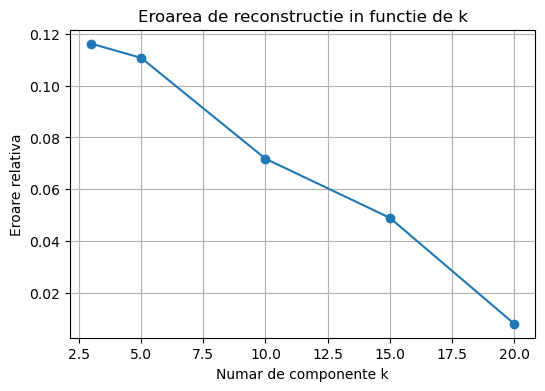

In [167]:
def afiseaza_grafic_erori_reconstructie(k_values, erori):
    plt.figure(figsize=(6, 4))
    plt.plot(k_values, erori, marker="o")
    plt.xlabel("Numar de componente k")
    plt.ylabel("Eroare relativa")
    plt.title("Eroarea de reconstructie in functie de k")
    plt.grid(True)
    plt.show()

afiseaza_grafic_erori_reconstructie(k_values, erori_reconstructie)

In [169]:
assert len(erori_reconstructie) == len(k_values), "Nu s-au calculat toate erorile."

for i in range(len(erori_reconstructie) - 1):
    assert erori_reconstructie[i + 1] <= erori_reconstructie[i] + 1e-10, \
        "Eroarea ar trebui sa scada cand k creste."

print("Pasul 5 trecut: reconstructia fetelor pentru mai multe valori k functioneaza.")

Pasul 5 trecut: reconstructia fetelor pentru mai multe valori k functioneaza.


In [187]:
#Recunoaste faciala - ULTIMUL PAS DUȚI LASĂ-L PE OTNIEL -
def imparte_train_test(X, y, nr_train_per_persoana=4):
    """
    Imparte datele in train si test.

    Pentru fiecare persoana:
        - primele nr_train_per_persoana imagini merg in train
        - restul merg in test
    """
    persoane = np.unique(y)

    indici_train = []
    indici_test = []

    for persoana in persoane:
        indici_persoana = np.where(y == persoana)[0]

        for i in range(len(indici_persoana)):
            if i < nr_train_per_persoana:
                indici_train.append(indici_persoana[i])
            else:
                indici_test.append(indici_persoana[i])

    X_train = X[:, indici_train]
    y_train = y[indici_train]

    X_test = X[:, indici_test]
    y_test = y[indici_test]

    return X_train, y_train, X_test, y_test, indici_train, indici_test

X_train, y_train, X_test, y_test, indici_train, indici_test = imparte_train_test(
    X,
    y,
    nr_train_per_persoana=4
)

print("X_train.shape =", X_train.shape)
print("y_train.shape =", y_train.shape)
print("X_test.shape  =", X_test.shape)
print("y_test.shape  =", y_test.shape)

print("y_train =", y_train)
print("y_test  =", y_test)

print("------------------------------------")
mean_train = calculeaza_fata_medie(X_train)
X_train_centrata = centreaza_datele(X_train, mean_train)

U_train, S_train, Vt_train = svd_custom(X_train_centrata)

print("mean_train.shape       =", mean_train.shape)
print("X_train_centrata.shape =", X_train_centrata.shape)
print("U_train.shape          =", U_train.shape)
print("S_train.shape          =", S_train.shape)
print("Vt_train.shape         =", Vt_train.shape)

X_train.shape = (4096, 20)
y_train.shape = (20,)
X_test.shape  = (4096, 5)
y_test.shape  = (5,)
y_train = [0 0 0 0 1 1 1 1 2 2 2 2 3 3 3 3 4 4 4 4]
y_test  = [0 1 2 3 4]
------------------------------------
mean_train.shape       = (4096, 1)
X_train_centrata.shape = (4096, 20)
U_train.shape          = (4096, 19)
S_train.shape          = (19,)
Vt_train.shape         = (19, 20)


In [188]:
def proiecteaza_fete(X_date, mean_face, U, k):
    """
    Proiecteaza imaginile din X_date in spatiul generat de primele k eigenfaces.

    X_date are forma:
        (numar_pixeli, numar_imagini)

    Returneaza:
        W cu forma (k, numar_imagini)
    """
    k = min(k, U.shape[1])

    U_k = U[:, :k]

    X_c = centreaza_datele(X_date, mean_face)

    W = U_k.T @ X_c

    return W


def distanta_euclidiana(a, b):
    """
    Calculeaza distanta euclidiana intre doi vectori.
    """
    diferenta = a - b
    return norma_vector(diferenta)


def recunoaste_fata(x_test, mean_face, U, k, W_train, y_train):
    """
    Recunoaste o singura fata test folosind nearest neighbor in spatiul eigenfaces.
    """
    if len(x_test.shape) == 1:
        x_test = x_test.reshape(-1, 1)

    k = min(k, U.shape[1])
    U_k = U[:, :k]

    x_c = x_test - mean_face

    w_test = U_k.T @ x_c

    distanta_minima = None
    index_minim = -1

    for i in range(W_train.shape[1]):
        w_train_i = W_train[:, i].reshape(-1, 1)

        d = distanta_euclidiana(w_test, w_train_i)

        if distanta_minima is None or d < distanta_minima:
            distanta_minima = d
            index_minim = i

    predictie = y_train[index_minim]

    return predictie, distanta_minima, index_minim


def evalueaza_recunoastere(X_test, y_test, mean_face, U, k, W_train, y_train):
    """
    Evalueaza acuratetea modelului pe setul de test.
    """
    corecte = 0
    predictii = []
    distante = []
    indici_vecini = []

    for i in range(X_test.shape[1]):
        predictie, distanta, index_vecin = recunoaste_fata(
            X_test[:, i],
            mean_face,
            U,
            k,
            W_train,
            y_train
        )

        predictii.append(predictie)
        distante.append(distanta)
        indici_vecini.append(index_vecin)

        if predictie == y_test[i]:
            corecte += 1

    acuratete = corecte / X_test.shape[1]

    return acuratete, np.array(predictii), np.array(distante), np.array(indici_vecini)



k_values = [3, 5, 10, 15, 20]

acurateti = []

for k in k_values:
    k_real = min(k, U_train.shape[1])

    W_train = proiecteaza_fete(
        X_train,
        mean_train,
        U_train,
        k_real
    )

    acuratete, predictii, distante, indici_vecini = evalueaza_recunoastere(
        X_test,
        y_test,
        mean_train,
        U_train,
        k_real,
        W_train,
        y_train
    )

    acurateti.append(acuratete)

    print(f"\nk = {k}  folosit efectiv k_real = {k_real}")
    print("y_test    =", y_test)
    print("predictii =", predictii)
    print("acuratete =", acuratete)


k = 3  folosit efectiv k_real = 3
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 0]
acuratete = 0.8

k = 5  folosit efectiv k_real = 5
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 4]
acuratete = 1.0

k = 10  folosit efectiv k_real = 10
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 4]
acuratete = 1.0

k = 15  folosit efectiv k_real = 15
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 4]
acuratete = 1.0

k = 20  folosit efectiv k_real = 19
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 4]
acuratete = 1.0


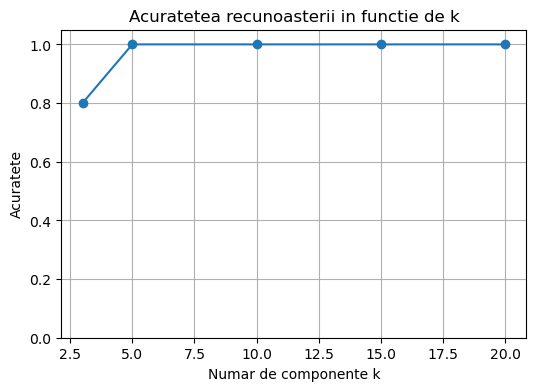

In [179]:
def afiseaza_grafic_acuratete(k_values, acurateti):
    plt.figure(figsize=(6, 4))
    plt.plot(k_values, acurateti, marker="o")
    plt.xlabel("Numar de componente k")
    plt.ylabel("Acuratete")
    plt.title("Acuratetea recunoasterii in functie de k")
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.show()

afiseaza_grafic_acuratete(k_values, acurateti)

Acuratete pentru k = 15 : 1.0
y_test    = [0 1 2 3 4]
predictii = [0 1 2 3 4]


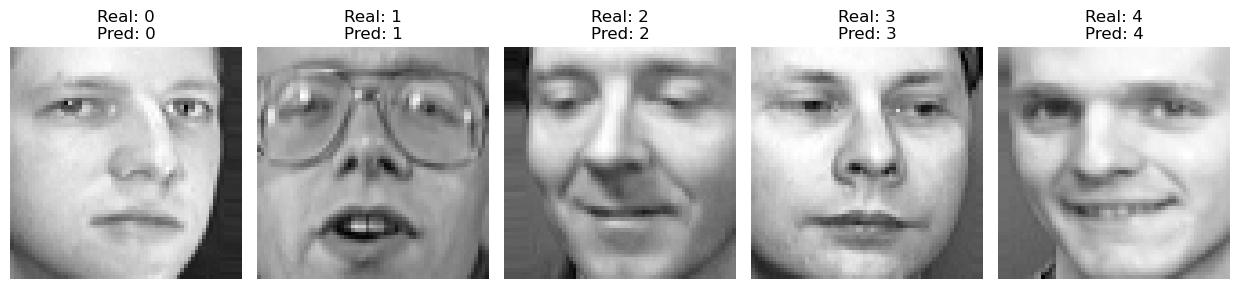

In [191]:
def afiseaza_predictii_test(X_test, y_test, predictii, image_shape=(64, 64)):
    """
    Afiseaza imaginile de test impreuna cu eticheta reala si predictia.
    """
    nr = X_test.shape[1]

    plt.figure(figsize=(2.5 * nr, 3))

    for i in range(nr):
        img = X_test[:, i].reshape(image_shape)

        plt.subplot(1, nr, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Real: {y_test[i]}\nPred: {predictii[i]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

k_afisare = 15
k_real = min(k_afisare, U_train.shape[1])

W_train = proiecteaza_fete(X_train, mean_train, U_train, k_real)

acuratete, predictii, distante, indici_vecini = evalueaza_recunoastere(
    X_test,
    y_test,
    mean_train,
    U_train,
    k_real,
    W_train,
    y_train
)

print("Acuratete pentru k =", k_afisare, ":", acuratete)
print("y_test    =", y_test)
print("predictii =", predictii)

afiseaza_predictii_test(X_test, y_test, predictii, image_shape=(64, 64))

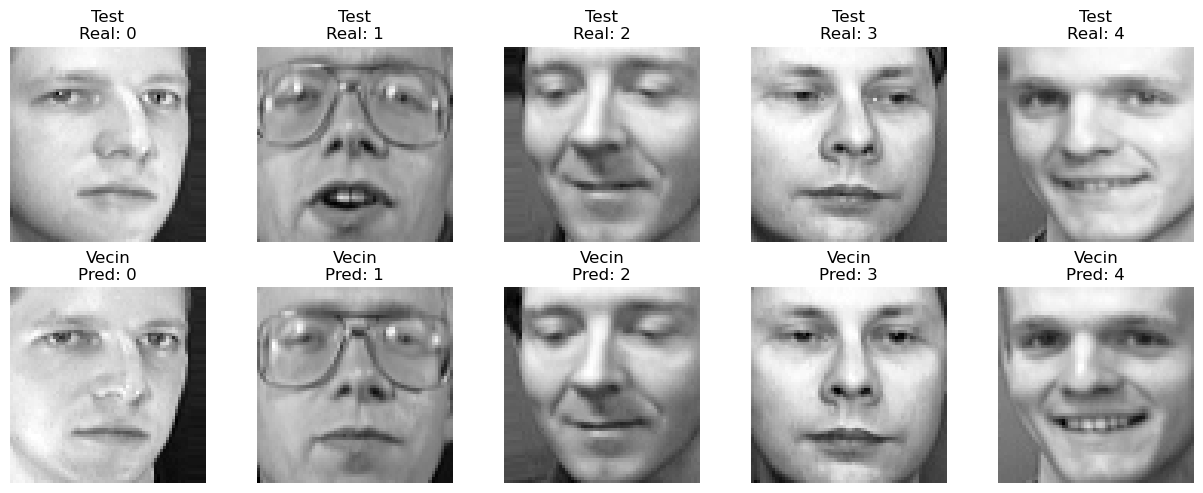

In [193]:
def afiseaza_test_si_vecin(X_test, y_test, X_train, y_train, indici_vecini, image_shape=(64, 64)):
    """
    Pentru fiecare imagine test, afiseaza imaginea test si imaginea de train cea mai apropiata.
    """
    nr = X_test.shape[1]

    plt.figure(figsize=(2.5 * nr, 5))

    for i in range(nr):
        index_vecin = indici_vecini[i]

        img_test = X_test[:, i].reshape(image_shape)
        img_vecin = X_train[:, index_vecin].reshape(image_shape)

        plt.subplot(2, nr, i + 1)
        plt.imshow(img_test, cmap="gray")
        plt.title(f"Test\nReal: {y_test[i]}")
        plt.axis("off")

        plt.subplot(2, nr, nr + i + 1)
        plt.imshow(img_vecin, cmap="gray")
        plt.title(f"Vecin\nPred: {y_train[index_vecin]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
afiseaza_test_si_vecin(
    X_test,
    y_test,
    X_train,
    y_train,
    indici_vecini,
    image_shape=(64, 64)
)


In [185]:
assert X_train.shape[1] == 20, "Ar trebui sa avem 20 imagini de antrenare."
assert X_test.shape[1] == 5, "Ar trebui sa avem 5 imagini de test."
assert len(acurateti) == len(k_values), "Nu s-au calculat toate acuratetile."

for acc in acurateti:
    assert 0.0 <= acc <= 1.0, "Acuratete invalida."

print("Pasul 6 trecut: recunoasterea faciala functioneaza.")

Pasul 6 trecut: recunoasterea faciala functioneaza.
